Read 26 files and 20,404 rows.


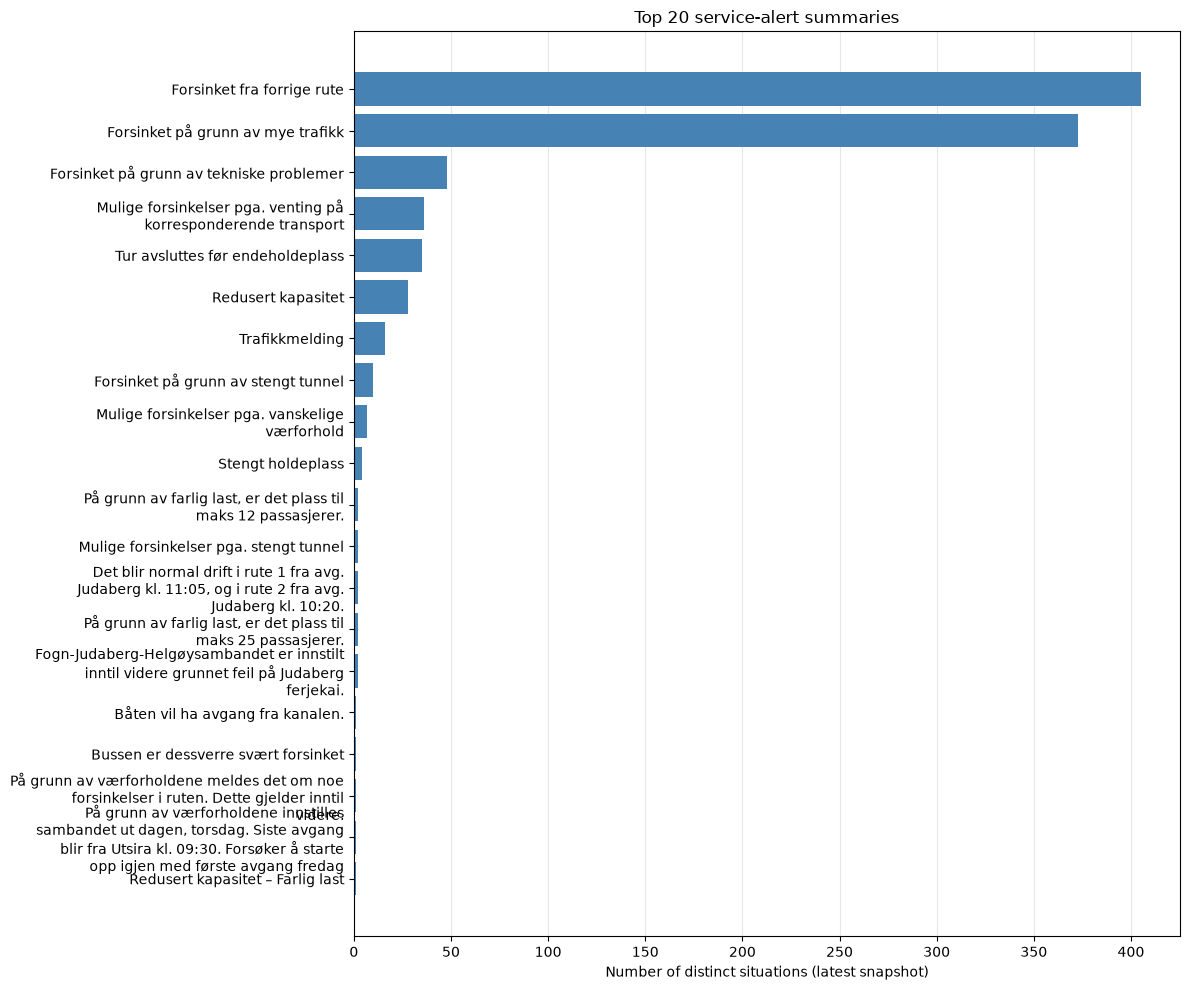

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

DATA_DIR = Path("/home/ubuntu/buspulse/tables/bronze-layer")
files = sorted(DATA_DIR.rglob("service_alerts.parquet"))

if not files:
    raise FileNotFoundError(f"No service_alerts.parquet files found under {DATA_DIR}")

alerts = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True,
)
print(f"Read {len(files)} files and {len(alerts):,} rows.")

alerts["snapshot_time"] = pd.to_datetime(
    alerts["snapshot_time"], utc=True, errors="coerce"
)

latest = (
    alerts.sort_values("snapshot_time", na_position="first")
    .drop_duplicates("situation_number", keep="last")
)

summary_counts = (
    latest["summary"]
    .fillna("Unknown")
    .str.strip()
    .value_counts()
    .head(20)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(12, max(6, 0.5 * len(summary_counts))))
labels = [textwrap.fill(str(label), width=45) for label in summary_counts.index]
ax.barh(labels, summary_counts.values, color="steelblue")
ax.set_title("Top 20 service-alert summaries")
ax.set_xlabel("Number of distinct situations (latest snapshot)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()